# Lab 1.3 — Data quality, bias, and imbalance

**Course:** AWS Certified Machine Learning Engineer – Associate (MLA-C02) · **Topic:** 1.3

Reproduce locally what AWS Glue Data Quality, DataBrew or Data Wrangler, and SageMaker Clarify do:

1. Validate data with DQDL-style rules.
2. Clean without data leakage.
3. Measure pre-training bias (CI and DPL).
4. Handle class imbalance.

No AWS account or credentials needed.

## 0. Setup

The reusable modules live in `src/`.

In [1]:
import sys

sys.path.insert(0, "src")

In [2]:
from pathlib import Path

import pandas as pd

import bias
import clean
import imbalance
import plots
import quality
from generate_data import generate

LANG = "en"
RULES = Path("rules.dqdl")
pd.set_option("display.width", 120)

## 1. Raw data

10,150 synthetic loan applications generated with a fixed seed. They deliberately include duplicates, invalid ages, missing and extreme `income`, 8–9% defaults, and underrepresented applicants over 60.

In [3]:
raw = generate()
Path("data").mkdir(exist_ok=True)
raw.to_csv("data/loans_raw.csv", index=False)
print(f"rows={len(raw):,}  default rate={raw['default'].mean():.1%}  missing income={raw['income'].isna().mean():.1%}")
raw.head()

rows=10,150  default rate=8.6%  missing income=8.9%


,application_id,age,income,loan_amount,credit_history_years,debt_ratio,default
0,APP-000621,43,35579.0,3625.0,19,0.506,0
1,APP-004385,29,47064.0,11639.0,2,0.355,0
2,APP-006794,57,63567.0,25914.0,38,0.216,0
3,APP-004562,35,27522.0,12656.0,17,0.353,0
4,APP-009264,25,32689.0,19345.0,5,0.571,0


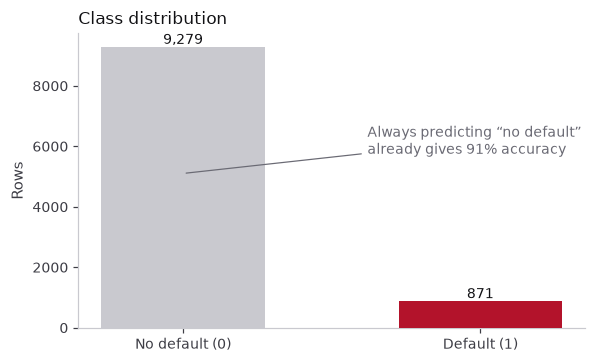

In [4]:
plots.class_distribution(raw, LANG);

With so few positives, a model that always predicts “no default” already gets high accuracy. That is why accuracy alone is misleading.

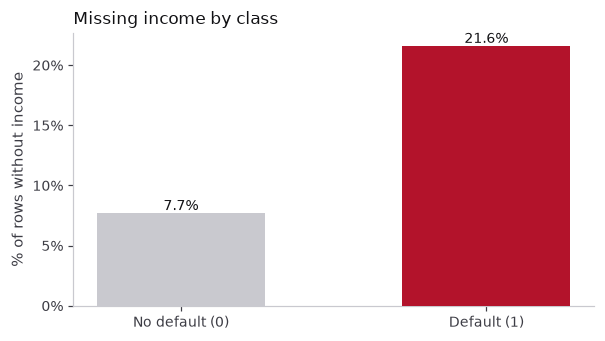

In [5]:
plots.missing_by_class(raw, LANG);

Defaults have more missing `income`: the missing value **is information**. So when imputing, add an indicator column.

## 2. Validate quality (Glue Data Quality equivalent)

`rules.dqdl` uses DQDL syntax. `quality.py` evaluates a subset of rules and computes the score: the percentage of rules that pass.

In [6]:
print(RULES.read_text())

Rules = [
  IsComplete "application_id",
  IsUnique "application_id",
  ColumnValues "age" between 18 and 100,
  Completeness "income" > 0.85,
  ColumnValues "default" in [0, 1],
  RowCount > 5000
]



In [7]:
score, results = quality.evaluate(raw, RULES)
quality.print_report("Raw data", score, results)


Raw data  —  data quality score: 67%
  [PASS] IsComplete "application_id"                   0 nulls
  [FAIL] IsUnique "application_id"                     150 duplicated values
  [FAIL] ColumnValues "age" between 18 and 100         15 values out of range
  [PASS] Completeness "income" > 0.85                  completeness = 0.911
  [PASS] ColumnValues "default" in [0, 1]              0 values not allowed
  [PASS] RowCount > 5000                               10150 rows


> In a Glue ETL job, the *Evaluate Data Quality* transform can **stop the job** before loading the data when a rule fails.

## 3. Clean without data leakage

1. Drop duplicates and invalid records.
2. Split into training and test sets with **stratification** and shuffling.
3. Compute the median and IQR bounds **on the training split only**.
4. Impute, add `income_missing`, and clip outliers in both sets.

In [8]:
valid = clean.drop_invalid(raw)
train, test = clean.split(valid)
stats = clean.fit_cleaning(train)  # solo entrenamiento / training split only
train, test = clean.apply_cleaning(train, stats), clean.apply_cleaning(test, stats)

print(f"{len(raw):,} -> {len(valid):,} rows after removing duplicates and invalid ages")
print(f"income median={stats['median']:,.0f}  IQR bounds=[{stats['low']:,.0f}, {stats['high']:,.0f}]")
print(f"default rate  train={train['default'].mean():.2%}  test={test['default'].mean():.2%}")

10,150 -> 9,985 rows after removing duplicates and invalid ages
income median=40,810  IQR bounds=[-14,073, 100,467]
default rate  train=8.64%  test=8.61%


In [9]:
score, results = quality.evaluate(pd.concat([train, test]), RULES)
quality.print_report("Clean data", score, results)


Clean data  —  data quality score: 100%
  [PASS] IsComplete "application_id"                   0 nulls
  [PASS] IsUnique "application_id"                     0 duplicated values
  [PASS] ColumnValues "age" between 18 and 100         0 values out of range
  [PASS] Completeness "income" > 0.85                  completeness = 1.000
  [PASS] ColumnValues "default" in [0, 1]              0 values not allowed
  [PASS] RowCount > 5000                               9985 rows


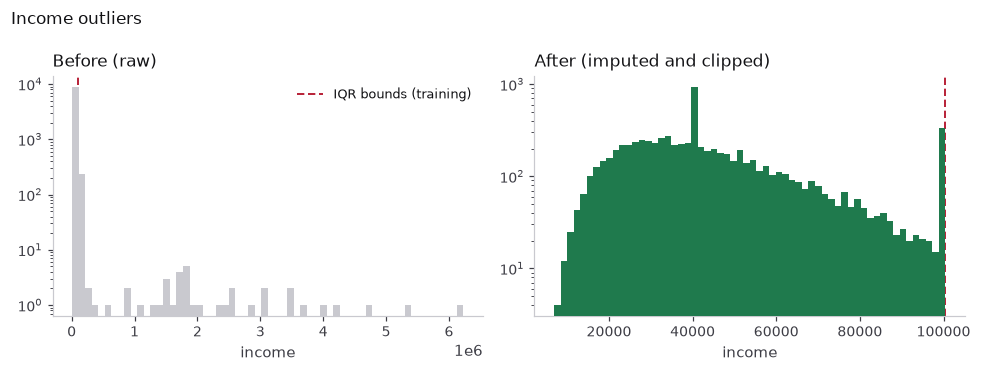

In [10]:
plots.income_before_after(raw, train, stats, LANG);

Clipping to the IQR bounds keeps the rows and reduces the influence of extremes. It is the equivalent of `REPLACE_OUTLIERS` in DataBrew or *Handle outliers* in Data Wrangler.

## 4. Pre-training bias (SageMaker Clarify definitions)

Facet **d** = over 60; facet **a** = everyone else.

- **CI** = (nₐ − n_d) / (nₐ + n_d): is facet d **underrepresented**? (0 = balanced)
- **DPL** = qₐ − q_d: does one facet get **more positive labels**? (0 = parity)

Neither one needs a model.

In [11]:
facet_d = valid["age"] > 60
report = bias.report(valid, facet_d, "default")
pd.Series(report).round(3)

n_a    8582.000
n_d    1403.000
q_a       0.081
q_d       0.122
CI        0.719
DPL      -0.041
dtype: float64

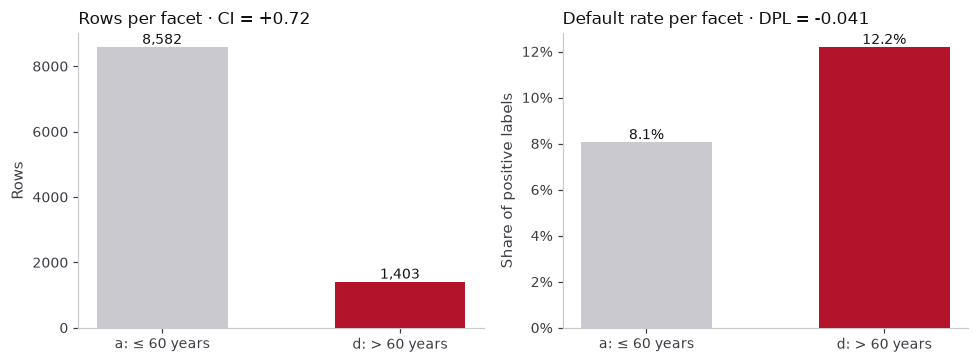

In [12]:
plots.facets(valid, facet_d, report, LANG);

CI > 0 means facet d is underrepresented. DPL < 0 means facet d has a higher share of defaults in the data. Before training, document the finding and look for more data on group d.

## 5. Class imbalance

The baseline is compared with `scale_pos_weight ≈ negatives / positives` and with SMOTE (**training split only**). The test set is **not resampled**: it must reflect real data.

In [13]:
metrics, predictions = imbalance.compare(train, test)
metrics

,accuracy,balanced_acc,recall,f1,roc_auc
always 'no default',0.914,0.500,0.000,0.000,0.500
xgboost baseline,0.915,0.530,0.064,0.115,0.720
scale_pos_weight=10.6,0.732,0.656,0.564,0.266,0.709
SMOTE (train only),0.688,0.637,0.576,0.241,0.696


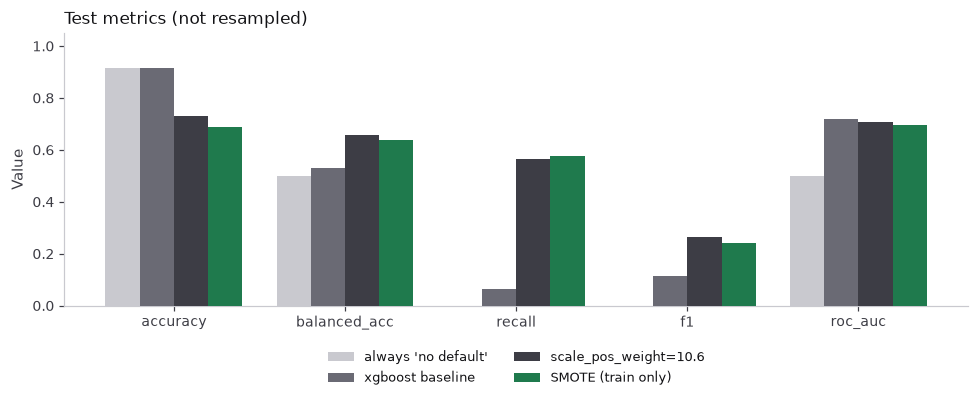

In [14]:
plots.metrics_comparison(metrics, LANG);

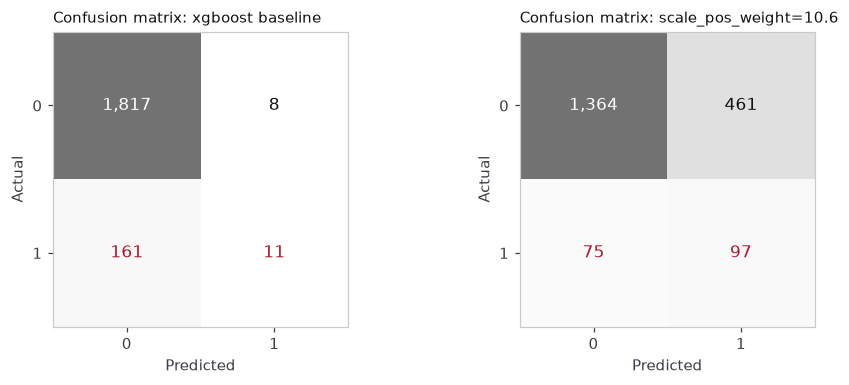

In [15]:
names = [n for n in predictions if n.startswith(("xgboost", "scale_pos_weight"))]
plots.confusion_matrices(test["default"], predictions, names, LANG);

The baseline barely catches any defaults (low recall). Weighting or resampling trades accuracy for higher recall and F1: those are the metrics the business cares about.

## 6. AWS equivalent

| This lab | On AWS | Main differences |
|---|---|---|
| `quality.py` + `rules.dqdl` | AWS Glue Data Quality (*Evaluate Data Quality*) | Glue supports many more rules, dynamic rules, anomaly detection, recommendations, and CloudWatch metrics. |
| `clean.py` | AWS Glue DataBrew or SageMaker Data Wrangler | Visual tools with reusable recipes or flows that scale. |
| `bias.py` | SageMaker Clarify pre-training metrics | Clarify no longer accepts new customers; AWS recommends computing them with pandas, as done here. |
| `imbalance.py` | SageMaker AI built-in XGBoost, Data Wrangler *Balance data* | Training on managed instances and automatic tuning with `validation:f1` or `validation:auc`. |

### Try this

- Change `Completeness "income" > 0.85` to `> 0.95` in `rules.dqdl` and rerun.
- Apply SMOTE **before** splitting the data and watch the test metrics inflate.
- Change the facet to `age < 25` and compare CI and DPL.